In [4]:
import pandas as pd

In [14]:
df = pd.read_csv(r"C:\Users\RITIKA\Downloads\archive\superstore.csv")
df.head(5)

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,...,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,...,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,...,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [16]:
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', '记录数', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='object')

In [18]:
df.shape

(51290, 27)

In [20]:
df = df[~df['Order.ID'].astype(str).str.startswith('C')] 
df.dropna(subset=["Customer.ID"], inplace=True)

df['Order.Date'] = pd.to_datetime(df['Order.Date'])
df['TotalPrice'] = df['Quantity'] * df['Profit']
df

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum,TotalPrice
15,Office Supplies,Los Angeles,United States,AR-105404,Andy Reiter,0.0,US,1,2012-04-11,US-2012-136987,...,Consumer,2012-04-14 00:00:00.000,Second Class,1.59,California,Paper,2012,North America,15,48.5392
25,Office Supplies,Los Angeles,United States,SW-202454,Scot Wooten,0.0,US,1,2013-03-13,US-2013-119270,...,Consumer,2013-03-17 00:00:00.000,Standard Class,1.30,California,Paper,2013,North America,11,17.9820
30,Office Supplies,Los Angeles,United States,JO-152804,Jas O'Carroll,0.0,US,1,2013-04-20,US-2013-115819,...,Consumer,2013-04-25 00:00:00.000,Second Class,3.87,California,Paper,2013,North America,16,40.8960
43,Office Supplies,Los Angeles,United States,PS-187604,Pamela Stobb,0.0,US,1,2013-09-30,US-2013-101497,...,Consumer,2013-10-02 00:00:00.000,Second Class,1.89,California,Paper,2013,North America,40,9.1056
45,Office Supplies,Los Angeles,United States,JE-157454,Joel Eaton,0.0,US,1,2013-10-09,US-2013-162026,...,Consumer,2013-10-09 00:00:00.000,Same Day,3.00,California,Paper,2013,North America,41,55.7640
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51259,Office Supplies,Los Angeles,United States,PF-192254,Phillip Flathmann,0.2,US,1,2013-12-30,US-2013-163258,...,Consumer,2014-01-03 00:00:00.000,Standard Class,1.11,California,Binders,2013,North America,53,11.7936
51260,Office Supplies,Los Angeles,United States,JP-161354,Julie Prescott,0.2,US,1,2013-12-31,US-2013-111528,...,Home Office,2013-12-31 00:00:00.000,Same Day,0.34,California,Binders,2013,North America,53,2.1546
51275,Office Supplies,Los Angeles,United States,JL-152354,Janet Lee,0.2,US,1,2014-09-03,US-2014-163657,...,Consumer,2014-09-07 00:00:00.000,Standard Class,3.38,California,Binders,2014,North America,36,32.7600
51278,Office Supplies,Los Angeles,United States,ES-140204,Erica Smith,0.2,US,1,2014-09-16,US-2014-163300,...,Consumer,2014-09-22 00:00:00.000,Standard Class,173.00,California,Binders,2014,North America,38,6188.4060


In [30]:
df = df.sort_values(['Customer.ID', 'Order.Date'])

df_order = df.groupby(['Customer.ID', 'Order.ID', 'Order.Date']).agg({
    'TotalPrice': 'sum'
}).reset_index()
df_order

,Customer.ID,Order.ID,Order.Date,TotalPrice
0,AA-103151,ID-2011-40953,2011-07-04,-1930.5435
1,AA-103151,ID-2014-42388,2014-08-25,-96.0300
2,AA-103151,ID-2014-65824,2014-01-07,54.6525
3,AA-103151,IN-2013-58152,2013-12-31,719.0400
4,AA-103151,IN-2014-55191,2014-12-23,39.9600
...,...,...,...,...
21082,ZD-219252,IT-2012-4926272,2012-08-17,-380.6460
21083,ZD-219253,MX-2012-105662,2012-11-26,14.6080
21084,ZD-219253,MX-2013-141698,2013-04-24,17.4400
21085,ZD-219253,MX-2014-168550,2014-06-18,209.2122


In [32]:
df_order['NextPurchaseDate'] = df_invoice.groupby('Customer.ID')['Order.Date'].shift(-1)
df_order

,Customer.ID,Order.ID,Order.Date,TotalPrice,NextPurchaseDate
0,AA-103151,ID-2011-40953,2011-07-04,-1930.5435,2014-08-25
1,AA-103151,ID-2014-42388,2014-08-25,-96.0300,2014-01-07
2,AA-103151,ID-2014-65824,2014-01-07,54.6525,2013-12-31
3,AA-103151,IN-2013-58152,2013-12-31,719.0400,2014-12-23
4,AA-103151,IN-2014-55191,2014-12-23,39.9600,NaT
...,...,...,...,...,...
21082,ZD-219252,IT-2012-4926272,2012-08-17,-380.6460,NaT
21083,ZD-219253,MX-2012-105662,2012-11-26,14.6080,2013-04-24
21084,ZD-219253,MX-2013-141698,2013-04-24,17.4400,2014-06-18
21085,ZD-219253,MX-2014-168550,2014-06-18,209.2122,NaT


In [36]:
df_order['DaysUntilNextPurchase'] = (df_order['NextPurchaseDate'] - df_order['Order.Date']).dt.days
df_order

,Customer.ID,Order.ID,Order.Date,TotalPrice,NextPurchaseDate,DaysUntilNextPurchase
0,AA-103151,ID-2011-40953,2011-07-04,-1930.5435,2014-08-25,1148.0
1,AA-103151,ID-2014-42388,2014-08-25,-96.0300,2014-01-07,-230.0
2,AA-103151,ID-2014-65824,2014-01-07,54.6525,2013-12-31,-7.0
3,AA-103151,IN-2013-58152,2013-12-31,719.0400,2014-12-23,357.0
4,AA-103151,IN-2014-55191,2014-12-23,39.9600,NaT,NaN
...,...,...,...,...,...,...
21082,ZD-219252,IT-2012-4926272,2012-08-17,-380.6460,NaT,NaN
21083,ZD-219253,MX-2012-105662,2012-11-26,14.6080,2013-04-24,149.0
21084,ZD-219253,MX-2013-141698,2013-04-24,17.4400,2014-06-18,420.0
21085,ZD-219253,MX-2014-168550,2014-06-18,209.2122,NaT,NaN


In [38]:
df_order['NumPurchasesSoFar'] = df_order.groupby('Customer.ID').cumcount() + 1

df_order['TotalSpentSoFar'] = df_order.groupby('Customer.ID')['TotalPrice'].cumsum()

first_purchase = df_order.groupby('Customer.ID')['Order.Date'].transform('min')
print(first_purchase)
df_order['RecencyDays'] = (df_order['Order.Date'] - first_purchase).dt.days
df_order

0       2011-07-04
1       2011-07-04
2       2011-07-04
3       2011-07-04
4       2011-07-04
           ...    
21082   2011-02-21
21083   2012-11-26
21084   2012-11-26
21085   2012-11-26
21086   2013-05-06
Name: Order.Date, Length: 21087, dtype: datetime64[ns]


,Customer.ID,Order.ID,Order.Date,TotalPrice,NextPurchaseDate,DaysUntilNextPurchase,NumPurchasesSoFar,TotalSpentSoFar,RecencyDays
0,AA-103151,ID-2011-40953,2011-07-04,-1930.5435,2014-08-25,1148.0,1,-1930.5435,0
1,AA-103151,ID-2014-42388,2014-08-25,-96.0300,2014-01-07,-230.0,2,-2026.5735,1148
2,AA-103151,ID-2014-65824,2014-01-07,54.6525,2013-12-31,-7.0,3,-1971.9210,918
3,AA-103151,IN-2013-58152,2013-12-31,719.0400,2014-12-23,357.0,4,-1252.8810,911
4,AA-103151,IN-2014-55191,2014-12-23,39.9600,NaT,NaN,5,-1212.9210,1268
...,...,...,...,...,...,...,...,...,...
21082,ZD-219252,IT-2012-4926272,2012-08-17,-380.6460,NaT,NaN,7,-3277.7505,543
21083,ZD-219253,MX-2012-105662,2012-11-26,14.6080,2013-04-24,149.0,1,14.6080,0
21084,ZD-219253,MX-2013-141698,2013-04-24,17.4400,2014-06-18,420.0,2,32.0480,149
21085,ZD-219253,MX-2014-168550,2014-06-18,209.2122,NaT,NaN,3,241.2602,569


In [44]:
df_order['AvgOrderValue'] = df_order['TotalSpentSoFar'] / df_order['NumPurchasesSoFar']

df_order

,Customer.ID,Order.ID,Order.Date,TotalPrice,NextPurchaseDate,DaysUntilNextPurchase,NumPurchasesSoFar,TotalSpentSoFar,RecencyDays,AvgOrderValue
0,AA-103151,ID-2011-40953,2011-07-04,-1930.5435,2014-08-25,1148.0,1,-1930.5435,0,-1930.543500
1,AA-103151,ID-2014-42388,2014-08-25,-96.0300,2014-01-07,-230.0,2,-2026.5735,1148,-1013.286750
2,AA-103151,ID-2014-65824,2014-01-07,54.6525,2013-12-31,-7.0,3,-1971.9210,918,-657.307000
3,AA-103151,IN-2013-58152,2013-12-31,719.0400,2014-12-23,357.0,4,-1252.8810,911,-313.220250
4,AA-103151,IN-2014-55191,2014-12-23,39.9600,NaT,NaN,5,-1212.9210,1268,-242.584200
...,...,...,...,...,...,...,...,...,...,...
21082,ZD-219252,IT-2012-4926272,2012-08-17,-380.6460,NaT,NaN,7,-3277.7505,543,-468.250071
21083,ZD-219253,MX-2012-105662,2012-11-26,14.6080,2013-04-24,149.0,1,14.6080,0,14.608000
21084,ZD-219253,MX-2013-141698,2013-04-24,17.4400,2014-06-18,420.0,2,32.0480,149,16.024000
21085,ZD-219253,MX-2014-168550,2014-06-18,209.2122,NaT,NaN,3,241.2602,569,80.420067


In [46]:
df_train = df_order.dropna(subset=['DaysUntilNextPurchase'])
df_train

,Customer.ID,Order.ID,Order.Date,TotalPrice,NextPurchaseDate,DaysUntilNextPurchase,NumPurchasesSoFar,TotalSpentSoFar,RecencyDays,AvgOrderValue
0,AA-103151,ID-2011-40953,2011-07-04,-1930.5435,2014-08-25,1148.0,1,-1930.5435,0,-1930.543500
1,AA-103151,ID-2014-42388,2014-08-25,-96.0300,2014-01-07,-230.0,2,-2026.5735,1148,-1013.286750
2,AA-103151,ID-2014-65824,2014-01-07,54.6525,2013-12-31,-7.0,3,-1971.9210,918,-657.307000
3,AA-103151,IN-2013-58152,2013-12-31,719.0400,2014-12-23,357.0,4,-1252.8810,911,-313.220250
5,AA-103152,ES-2012-2960821,2012-05-16,189.6300,2013-11-27,560.0,1,189.6300,0,189.630000
...,...,...,...,...,...,...,...,...,...,...
21079,ZD-219252,ES-2014-5329048,2014-12-30,422.0355,2012-07-13,-900.0,4,-2932.7625,1408,-733.190625
21080,ZD-219252,IT-2012-2197138,2012-07-13,-287.9820,2012-12-12,152.0,5,-3220.7445,508,-644.148900
21081,ZD-219252,IT-2012-3146139,2012-12-12,323.6400,2012-08-17,-117.0,6,-2897.1045,660,-482.850750
21083,ZD-219253,MX-2012-105662,2012-11-26,14.6080,2013-04-24,149.0,1,14.6080,0,14.608000


In [50]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

features = ['NumPurchasesSoFar', 'TotalSpentSoFar', 'RecencyDays', 'AvgOrderValue']
X = df_train[features]
y = df_train['DaysUntilNextPurchase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [52]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))


R² Score: 0.29184163538474817
RMSE: 389.9963246824177


C:\Users\RITIKA\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


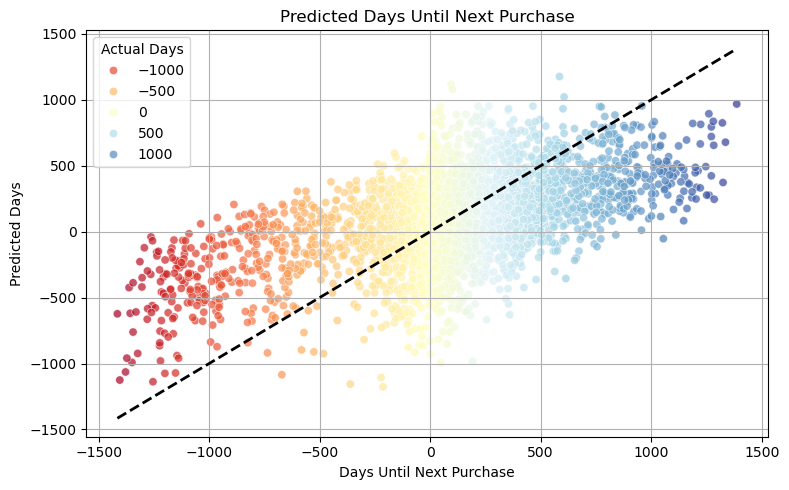

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

plt.figure(figsize=(8, 5))

sns.scatterplot(data=results_df, x='Actual', y='Predicted', hue='Actual',
             palette='RdYlBu', alpha=0.7)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)

plt.title('Predicted Days Until Next Purchase')
plt.xlabel('Days Until Next Purchase')
plt.ylabel('Predicted Days')
plt.legend(title="Actual Days", loc='upper left')
plt.grid(True)

plt.tight_layout()
plt.show()

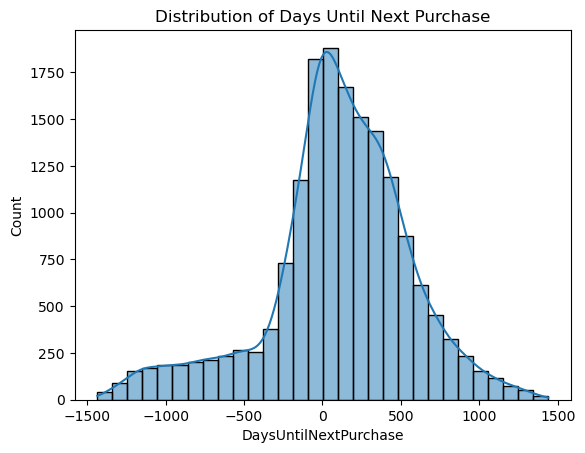

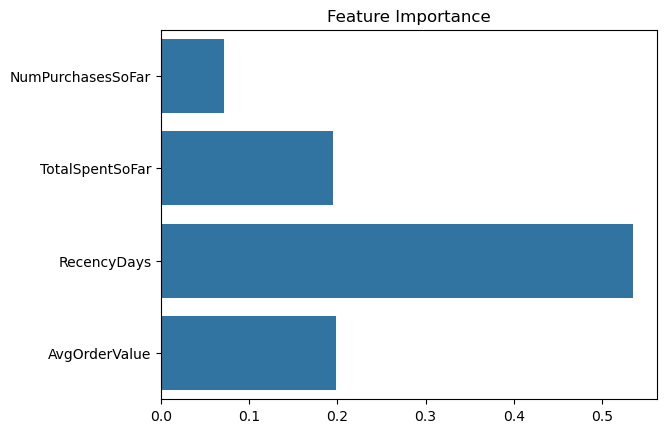

In [77]:
sns.histplot(df_train['DaysUntilNextPurchase'], bins=30, kde=True)
plt.title("Distribution of Days Until Next Purchase")
plt.show()

importances = rf.feature_importances_
sns.barplot(x=importances, y=features)
plt.title("Feature Importance")
plt.show()
